<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;"> Критерии. Основы</span></h2>

In [1]:
from typing import Any, Callable, Dict, Tuple, Union
import numpy as np
from scipy import stats as sps
from criteria_runtime import _validate_alpha, _validate_n

In [2]:
from criteria_runtime import CALCULATIONS_JS
from criteria_visualization import render_demo

Предположим, что мы работаем в [Шедевруме](https://shedevrum.ai/). Наши инженеры дообучили новую версию модели для генерации изображений, которая показала хорошие результаты на внутренних тестах. Теперь возникает следующий немаловажный вопрос: **стоит ли запускать новую модель в продакшен?**

На первый взгляд кажется, что да. Однако, результаты имеются только на внутренних ML-метриках, которые могут **не всегда коррелировать с предпочтениями пользователей.**

К счастью, Шедеврум обычно предлагает пользователю сразу несколько картинок. Тогда мы можем выдавать одну картинку сгенерированную одной моделью, а другую &mdash; другой моделью. Тогда мы сможем оценить, какой из моделей пользователи отдают наибольшее предпочтение.

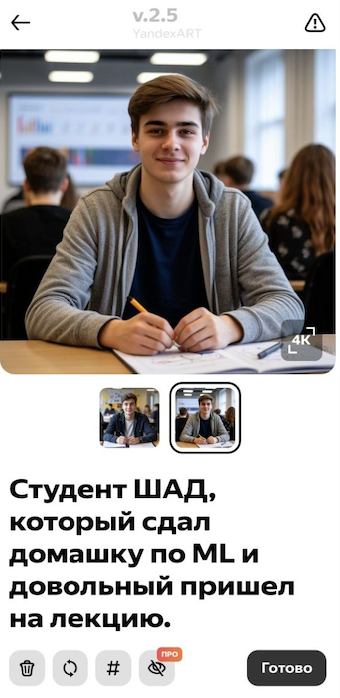

Пусть у нас в распоряжении 200 участников теста. Каждому пользователю одновременно показывают две картинки — одну сгенерированную старой моделью, другую новой, при этом пользователям не сообщают, какая картинка от какой версии. Мы просим их выбрать, какое изображение им нравится больше. По окончании эксперимента получаем следующие результаты:

* новую модель предпочли 150 человек
* старую модель предпочли 50 человек

Вроде бы новая модель работает гораздо лучше старой. А если бы результаты эксперимента получились бы такими:

* новую модель предпочли 120 человек
* старую модель предпочли 80 человек

Новая модель, *кажется*, все еще лучше, однако разница уже не такая внушительная. Теперь третья ситуация:

* новую модель предпочли 105 человек
* старую модель предпочли 95 человека

Новая модель все еще показала результат лучше, но разница всего лишь в 10 человек. А вдруг это просто случайность? Может пользователи просто случайно чаще выбирали правую (или левую) картинку, независимо от качества? Может тогда и разница в 40 человек тоже случайность?

Как принять взвешенное, технически обоснованное решение, основанное не на интуиции "кажется, работает", а на данных? Для этого нам нужен механизм, который оценит, насколько реально улучшение от новой модели, отделив его от простой случайности. Этот механизм — проверка статистических гипотез.

> *Замечание.* Приведенная выше задача является не совсем типичным примером АБ-тестирования. Она была выбрана в силу того, что для данного эксперимента требуется только одна выборка. С этим проще работать в начале изучения темы проверки статистических гипотез.

Пусть
* $\mathscr{P} = \{\mathsf{P}_\theta\ |\ \theta \in \Theta\}$ &mdash; семейство распределений на выборочном пространстве  $\mathscr{X}$.
* $X = (X_1, ... X_n)$ &mdash; выборка из неизвестного распределения $\mathsf{P} \in \mathscr{P} $

Рассматриваем гипотезу $\mathsf{H}_0\colon \theta \in \Theta_0$, где $\Theta_0 \subset \Theta$. Критерием для проверки  $\mathsf{H}_0$   является множество $S \subset  \mathscr{X}$, если  $\mathsf{H}_0$ отвергается $\Leftrightarrow$ $X \in S$.





Для примера посмотрим на простой критерий $S = \{ |T(x)| \geq 2  \}$, где $T(X) = \overline{X}$. Такой критерий будет отвергать только в том случае, если модуль статистики $T$ будет больше двух.  

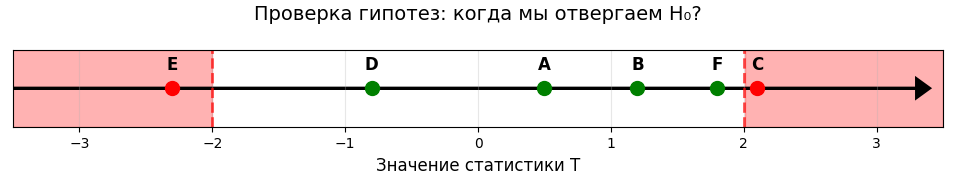

## Ошибка первого рода

В исходном примере мы хотим  проверить следующую гипотезу:

* $\mathsf{H}_0$ — разницы между разными версиями нет
* $\mathsf{H}_1$ — новая модель лучше


Для начала мы вспомним, что такое **ошибка первого рода**. Это ситуация, при которой **в результате проверки мы отвергли нулевую гипотезу, которая на самом деле оказалась верной**. В нашем случае, мы сказали что новая модель на самом деле лучше и ее выкатили в продакшн, т.к. посчитали, что пользователи предпочитали генерации от новой модели. А на самом деле разницы никакой не было (а может вообще хуже стало).

На лекции мы вводили параметр **$\alpha$ — уровень значимости критерия**. По сути это **ограничение на значение вероятности ошибки I рода**. Иначе говоря, ограничение на вероятность того, что выбранный нами критерий отвергнет нулевую гипотезу, если она верна. Таким образом мы задаем насколько строгим должен быть наш критерий, и насколько веским должны быть наши доказательства, чтобы отвергнуть нулевую гипотезу.

Итак, если разницы между моделями нет, то пользователи будут случайно выбирать одно из двух изображений, т.е. вероятность выбора картинки, сгенерированной новой моделью = $1/2$ или $\mathsf{H}_0 = 1/2$.

Прежде зададимся вопросом, а зачем все усложнять? Пусть гипотеза не будет отвергаться только когда $\sum\limits_{i=1}^n X_i = 100$, то есть в выборке ровно половина единиц.

In [3]:
def quite_logical_criteria(X: np.ndarray) -> int:
    r"""Проверяет равенство суммы наблюдений половине размера выборки.

    Аргументы:
        X : np.ndarray
            Одномерная выборка наблюдений Бернулли: значения 0 или 1.

    Возвращает:
        int
            1, если $\mathsf{H}_0$ отвергается; 0, если сумма равна половине длины выборки.
    """
    return int(np.sum(X) != len(X) / 2)

Давайте оценим вероятность ошибки первого рода у этого критерия. Напомним, мы фиксируем $\alpha = 0.05$ и хотим, чтобы критерий совершал ошибку первого рода с вероятностью не более $\alpha$.

Для оценки вероятности ошибки применим метод Монте-Карло:
1. Генерируем выборки размера $n$ из $\mathsf{H}_0$. Число $n$ совпадает с размером выборки, выделенной для тестирования гипотезы.
2. Применяем критерий, сохраняем результат тестирования $I \in \{0, 1\}$, где $I=1$ в случае отвержения верной гипотезы $\mathsf{H}_0$.
3. Повторяем шаги 1-2 независимо $k$ раз, получая тем самым выборку $I_1, ..., I_k \sim Bern(P(I_S))$
4. Вычисляем долю случаев, в которых критерий отклонил основную гипотезу, и строим доверительный интервал по бернуллиевской выборке.

In [4]:
def conf_int(sample_len: int, sample_sum: int, alpha: float = 0.95) -> Tuple[float, float]:
    r"""Вычисляет доверительный интервал Вильсона для вероятности успеха.

    Аргументы:
        sample_len : int
            Положительное количество наблюдений.
        sample_sum : int
            Количество успехов от 0 до sample_len включительно.
        alpha : float, по умолчанию 0.95
            Уровень доверия интервала, строго между 0 и 1.

    Возвращает:
        tuple[float, float]
            Нижняя и верхняя границы интервала для вероятности успеха.
    """
    _validate_n(sample_len)
    _validate_alpha(alpha)
    if not 0 <= sample_sum <= sample_len:
        raise ValueError("Количество успехов должно быть от 0 до размера выборки")
    z = sps.norm.ppf((1 + alpha) / 2)
    p_hat = sample_sum / sample_len
    denominator = 1 + z**2 / sample_len
    centre = (p_hat + z**2 / (2 * sample_len)) / denominator
    half_width = (
        z * np.sqrt(p_hat * (1 - p_hat) / sample_len + z**2 / (4 * sample_len**2)) / denominator
    )
    return float(max(0, centre - half_width)), float(min(1, centre + half_width))


def estimate_1error(
    crit: Callable[[np.ndarray], int], n_iter: int = 10000, p0=0.5, sample_size: int = 100
) -> Tuple[float, Tuple[float, float]]:
    r"""Оценивает ошибку первого рода методом Монте-Карло при при справедливости $\mathsf{H}_0$.

    Аргументы:
        crit : Callable[[np.ndarray], int]
            Критерий, принимающий выборку и возвращающий 1 при отвержении
            нулевой гипотезы и 0 в противном случае.
        n_iter : int, по умолчанию 10000
            Положительное количество независимых повторений эксперимента.
        p0 : float, по умолчaнию 0.5
            Значение из нулевой гипотезы.
        sample_size : int, по умолчанию 100
            Положительное количество наблюдений Бернулли с $p = p0$ в каждом повторении.

    Возвращает:
        tuple[float, tuple[float, float]]
            Доля отвержений нулевой гипотезы и границы доверительного интервала
            Вильсона с уровнем доверия 0.95 для этой доли.
    """
    _validate_n(n_iter)
    _validate_n(sample_size)
    n_reject = sum(crit(np.random.binomial(1, p0, size=sample_size)) for _ in range(n_iter))
    return n_reject / n_iter, conf_int(n_iter, n_reject)

In [5]:
alpha_est, (left, right) = estimate_1error(quite_logical_criteria, sample_size=200)

print(f"Оценка вероятности ошибки первого рода: {alpha_est:.3}")
print(f"Д.И.: ({left:.3f}, {right:.3f})")

Оценка вероятности ошибки первого рода: 0.944
Д.И.: (0.939, 0.948)


Ой-ей, все очень плохо... Оценка вероятности ошибки первого рода очень большая.

Давайте возьмем другой критерий, например, $S = \left\{T(x) \geqslant c_\alpha\right\}$, где $T(X) = \sum\limits_{i=1}^n X_i$, где
$c_\alpha = u_{1-\alpha} + 1$, где $u_p$ &mdash; $p$-квантиль $Bin(n, 0.5)$. Здесь $c_\alpha$ подбирался теоретически исходя из уровня значимости $\alpha$, который мы заранее задали. Проверим с помощью метода Монте-Карло и этот критерий.

In [6]:
def binomial_critical_value(sample_size: int, p0=0.5, alpha: float = 0.05) -> int:
    r"""Вычисляет минимальную сумму успехов, при которой отвергается $\mathsf{H}_0$.

    Аргументы:
        sample_size : int
            Положительное количество наблюдений Бернулли.
        p0 : float, по умолчaнию 0.5
            Значение из нулевой гипотезы.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        int
            Порог $c_{\alpha} = u_{1-\alpha} + 1$, где $u_{1-\alpha}$ — квантиль
            распределения $\Binom(\mathrm{sample\_size}, 0.5)$.
    """
    _validate_n(sample_size)
    _validate_alpha(alpha)
    return int(sps.binom.ppf(1 - alpha, sample_size, p0)) + 1


def sum_criteria(X: np.ndarray, p0=0.5, alpha: float = 0.05) -> int:
    r"""Проверяет $\mathsf{H}_0: p = p_0$ против $\mathsf{H}_1: p > p_0$ по сумме успехов.

    Аргументы:
        X : np.ndarray
            Непустая одномерная выборка наблюдений Бернулли: значения 0 или 1.
        p0 : float, по умолчaнию 0.5
            Значение из нулевой гипотезы.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        int
            1, если сумма наблюдений не меньше критического значения $c_{\alpha}$;
            0, если нулевая гипотеза не отвергается.
    """
    return int(np.sum(X) >= binomial_critical_value(len(X), p0, alpha))

In [7]:
alpha_est, (left, right) = estimate_1error(sum_criteria, sample_size=200)

print(f"Оценка вероятности ошибки первого рода: {alpha_est:.3f}")
print(f"Д.И.: ({left:.3f}, {right:.3f})")

Оценка вероятности ошибки первого рода: 0.041
Д.И.: (0.037, 0.045)


Вот тут у нас все хорошо.

Смоделируем описанную ситуацию. Будем варьировать количество пользователей и параметр $\alpha$ и смотреть как меняется критерий. Кроме того мы будем знать истинную вероятность выбора картинки от новой модели (чего в реальной жизни мы знать никак не можем).

In [8]:
def generate_experiment_data(sample_size: int, true_p: float) -> Tuple[int, float]:
    r"""Генерирует результат одного биномиального эксперимента.

    Аргументы:
        sample_size : int
            Положительное количество независимых испытаний Бернулли.
        true_p : float
            Истинная вероятность успеха от 0 до 1 включительно.

    Возвращает:
        tuple[int, float]
            Наблюдаемое количество успехов и их доля в выборке.
    """
    _validate_n(sample_size)
    if not 0 <= true_p <= 1:
        raise ValueError("Вероятность должна находиться между 0 и 1")
    observed_success = int(np.random.binomial(sample_size, true_p))
    return observed_success, observed_success / sample_size


def binomial_distribution(sample_size: int, alpha: float = 0.05) -> Dict[str, Any]:
    r"""Вычисляет биномиальное распределение при $\mathsf{H}_0$ и зону отвержения.

    Аргументы:
        sample_size : int
            Положительное количество наблюдений Бернулли.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        dict[str, Any]
            x : np.ndarray размера sample_size + 1
                Возможные количества успехов от 0 до sample_size.
            pmf_h0 : np.ndarray того же размера
                Вероятности этих количеств при $p = 0.5$.
            critical_value : int
                Минимальное количество успехов для отвержения нулевой гипотезы.
            reject_mask : np.ndarray типа bool того же размера
                Маска значений x, входящих в зону отвержения.
            actual_alpha : float
                Точная вероятность ошибки первого рода для выбранного порога.
    """
    critical = binomial_critical_value(sample_size, alpha)
    x = np.arange(sample_size + 1)
    return {
        "x": x,
        "pmf_h0": sps.binom.pmf(x, sample_size, 0.5),
        "critical_value": critical,
        "reject_mask": x >= critical,
        "actual_alpha": float(sps.binom.sf(critical - 1, sample_size, 0.5)),
    }


def binomial_critical_curve(sample_size: int, alpha_range: Any = None) -> Dict[str, Any]:
    r"""Вычисляет зависимость биномиальной квантили $u_{1-\alpha}$ от уровня значимости.

    Аргументы:
        sample_size : int
            Положительное количество наблюдений Бернулли.
        alpha_range : array-like или None, по умолчанию None
            Уровни значимости строго между 0 и 1. При None используются
            1000 равномерно расположенных значений от 0.001 до 0.5.

    Возвращает:
        dict[str, np.ndarray]
            alpha : np.ndarray
                Переданные или автоматически созданные уровни значимости.
            quantile : np.ndarray той же формы
                Квантили $u_{1-\alpha}$ распределения
                $\operatorname{Bin}(\mathrm{sample\_size}, 0.5)$.
                Порог отвержения равен quantile + 1.
    """
    _validate_n(sample_size)
    alpha_range = np.linspace(0.001, 0.5, 1000) if alpha_range is None else np.asarray(alpha_range)
    if np.any((alpha_range <= 0) | (alpha_range >= 1)):
        raise ValueError("Значения alpha должны находиться между 0 и 1")
    return {"alpha": alpha_range, "quantile": sps.binom.ppf(1 - alpha_range, sample_size, 0.5)}

In [9]:
render_demo("binomial", calculations_js=CALCULATIONS_JS)

Что показывает эта визуализация:

* Распределение случайного выбора &mdash; как выглядел бы мир, если бы $\mathsf{H}_0$ была правдой

* Зона отвержения &mdash; красные столбцы показывают, какие результаты считались бы "позрительными" для случайного выбора

* Критическое значение &mdash; сколько раз необходимо выбрать новую модель,  чтобы мы сказали, что новая модель лучше

* Наш результат &mdash; черная пунктирная линия показывает, что мы наблюдали в эксперименте

* Как меняется порог отсечения при различных значениях $\alpha$

**Выводы**

Чем меньше $\alpha$, тем строже критерий, а значит выше порог отвержения, и таким образом нам сложнее отвергнуть нулевую гипотезу. Однако при этом мы увеличиваем вероятность не увидеть разницы, когда она на самом деле есть.



## Ошибка второго рода


Хорошо, если ошибка I рода для нас является наиболее критичной, то почему бы нам просто не сделать $\alpha = 0$? В целом, нам это никто не запрещает, но такой критерий вообще ничего не будет отвергать, даже в тех случаях когда в действительности новая модель лучше. **Таким образом мы не отвергнем неверную гипотезу, когда должны были это сделать, т.е. совершим ошибку второго рода.**

Наряду с ошибкой второго рода вводится функция **мощности**, которая **показывает насколько хорошо отвергает критерий на альтернативе**. Мощность используется для сравнения критериев при различных распределениях из альтернативы.

Рассмотрим выборку $X = (X_1, ... , X_n) \sim \mathcal{N}(\theta, 1) $
и гипотезу $\mathsf{H}_0 \colon  \theta = 0$ vs $\mathsf{H}_1 \colon  \theta > 0$

Теперь посмотрим на распределение статистики Вальда при различных значениях $\theta$ из альтернативы, и как при этом будут соотноситься между собой вероятности ошибок первого и второго рода и мощность.


In [10]:
def wald_right_sided(alpha: float, x_range: np.ndarray) -> tuple:
    r"""Вычисляет зоны правостороннего критерия Вальда для $\mathsf{H}_1: \theta > 0$.

    Аргументы:
        alpha : float
            Уровень значимости, строго между 0 и 1.
        x_range : np.ndarray
            Одномерный массив значений стандартизованной статистики.

    Возвращает:
        tuple[float, tuple[np.ndarray, np.ndarray], np.ndarray, str]
            z_critical : float
                Квантиль $u_{1-\alpha}$ стандартного нормального распределения.
            reject_zone : tuple[np.ndarray, np.ndarray]
                Пустой массив для левого хвоста и значения x_range больше z_critical для правого.
            retain_zone : np.ndarray
                Значения x_range, не превышающие z_critical.
            description : str
                Текстовое описание альтернативной гипотезы с обозначениями LaTeX.
    """
    _validate_alpha(alpha)
    x = np.asarray(x_range)
    c = float(sps.norm.ppf(1 - alpha))
    return c, (np.array([]), x[x > c]), x[x <= c], r"Правосторонний $\mathsf{H}_1: \theta > 0$"


def wald_left_sided(alpha: float, x_range: np.ndarray) -> tuple:
    r"""Вычисляет зоны левостороннего критерия Вальда для $\mathsf{H}_1: \theta < 0$.

    Аргументы:
        alpha : float
            Уровень значимости, строго между 0 и 1.
        x_range : np.ndarray
            Одномерный массив значений стандартизованной статистики.

    Возвращает:
        tuple[float, tuple[np.ndarray, np.ndarray], np.ndarray, str]
            z_critical : float
                Квантиль $u_{\alpha}$ стандартного нормального распределения.
            reject_zone : tuple[np.ndarray, np.ndarray]
                Значения x_range меньше z_critical для левого хвоста и пустой массив для правого.
            retain_zone : np.ndarray
                Значения x_range, не меньшие z_critical.
            description : str
                Текстовое описание альтернативной гипотезы с обозначениями LaTeX.
    """
    _validate_alpha(alpha)
    x = np.asarray(x_range)
    c = float(sps.norm.ppf(alpha))
    return c, (x[x < c], np.array([])), x[x >= c], r"Левосторонний $\mathsf{H}_1: \theta < 0$"


def wald_two_sided(alpha: float, x_range: np.ndarray) -> tuple:
    r"""Вычисляет зоны двустороннего критерия Вальда для $\mathsf{H}_1: \theta \ne 0$.

    Аргументы:
        alpha : float
            Уровень значимости, строго между 0 и 1.
        x_range : np.ndarray
            Одномерный массив значений стандартизованной статистики.

    Возвращает:
        tuple[float, tuple[np.ndarray, np.ndarray], np.ndarray, str]
            z_critical : float
                Верхняя критическая граница $u_{1-\alpha/2}$; нижняя равна -z_critical.
            reject_zone : tuple[np.ndarray, np.ndarray]
                Значения x_range меньше -z_critical и больше z_critical соответственно.
            retain_zone : np.ndarray
                Значения x_range между -z_critical и z_critical включительно.
            description : str
                Текстовое описание альтернативной гипотезы с обозначениями LaTeX.
    """
    _validate_alpha(alpha)
    x = np.asarray(x_range)
    c = float(sps.norm.ppf(1 - alpha / 2))
    return (
        c,
        (x[x < -c], x[x > c]),
        x[(x >= -c) & (x <= c)],
        r"Двусторонний $\mathsf{H}_1: \theta \ne 0$",
    )

In [11]:
def calculate_distributions(
    theta: float = 0.0, alpha: float = 0.05, alternative: str = "right"
) -> Dict[str, Any]:
    r"""Вычисляет нормальные распределения и характеристики критерия Вальда.

    Аргументы:
        theta : float, по умолчанию 0.0
            Сдвиг среднего распределения при альтернативной гипотезе $\mathsf{H}_1$.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.
        alternative : str, по умолчанию "right"
            Тип альтернативы: "right", "left" или "two_sided".

    Возвращает:
        dict[str, Any]
            x_range : np.ndarray размера 1000
                Сетка значений от min(-4, theta - 4) до max(4, theta + 4).
            pdf_h0, pdf_h1 : np.ndarray размера 1000
                Плотности $\mathcal{N}(0, 1)$ и $\mathcal{N}(\theta, 1)$ на этой сетке.
            z_critical : float
                Критическая граница; для двусторонней альтернативы используется
                пара границ -z_critical и z_critical.
            reject_zone : tuple[np.ndarray, np.ndarray]
                Значения сетки в левом и правом хвостах зоны отвержения.
            retain_zone : np.ndarray
                Значения сетки вне зоны отвержения.
            theta : float
                Переданный сдвиг среднего.
            alternative : str
                Переданный тип альтернативы.
            description : str
                Текстовое описание альтернативной гипотезы с обозначениями LaTeX.
            alpha : float
                Переданный уровень значимости.
            beta : float
                Вероятность ошибки второго рода при заданном theta.
            power : float
                Мощность критерия, равная $1 - \beta$.
    """
    functions = {"right": wald_right_sided, "left": wald_left_sided, "two_sided": wald_two_sided}
    if alternative not in functions:
        raise ValueError("alternative должен быть 'right', 'left' или 'two_sided'")
    x = np.linspace(min(-4, theta - 4), max(4, theta + 4), 1000)
    c, rejected, retained, description = functions[alternative](alpha, x)
    if alternative == "right":
        power = float(sps.norm.sf(c - theta))
    elif alternative == "left":
        power = float(sps.norm.cdf(c - theta))
    else:
        power = float(sps.norm.cdf(-c - theta) + sps.norm.sf(c - theta))
    return {
        "x_range": x,
        "pdf_h0": sps.norm.pdf(x),
        "pdf_h1": sps.norm.pdf(x, theta, 1),
        "z_critical": c,
        "reject_zone": rejected,
        "retain_zone": retained,
        "theta": theta,
        "alternative": alternative,
        "description": description,
        "alpha": alpha,
        "beta": 1 - power,
        "power": power,
    }

In [12]:
render_demo("wald", calculations_js=CALCULATIONS_JS)

Как видим, перекрытие распределений определяет, насколько сложно отличить $\mathsf{H}_0$ от $\mathsf{H}_1$. Т.е. чем сильнее отличается распределения друг от друга, тем меньше вероятность допусть ошибку второго рода и тем выше мощность критерия.

Мы только что рассмотрели правостороннюю альтернативу, т.е. мы отвергаем только очень большие значения статистики Вальда. Напомним основные альтернативы

* $\mathsf{H}_0\colon  \theta = 0$ vs $\mathsf{H}_1\colon  \theta > 0$ &mdash;  правостороняя альтернатива
* $\mathsf{H}_0\colon  \theta = 0$ vs $\mathsf{H}_1\colon  \theta < 0$ &mdash; левостороняя альтернатива
* $\mathsf{H}_0\colon  \theta = 0$ vs $\mathsf{H}_1\colon  \theta \neq 0$ &mdash; двустороняя альтернатива

Тогда мощность можно визуализировать следующим образом:

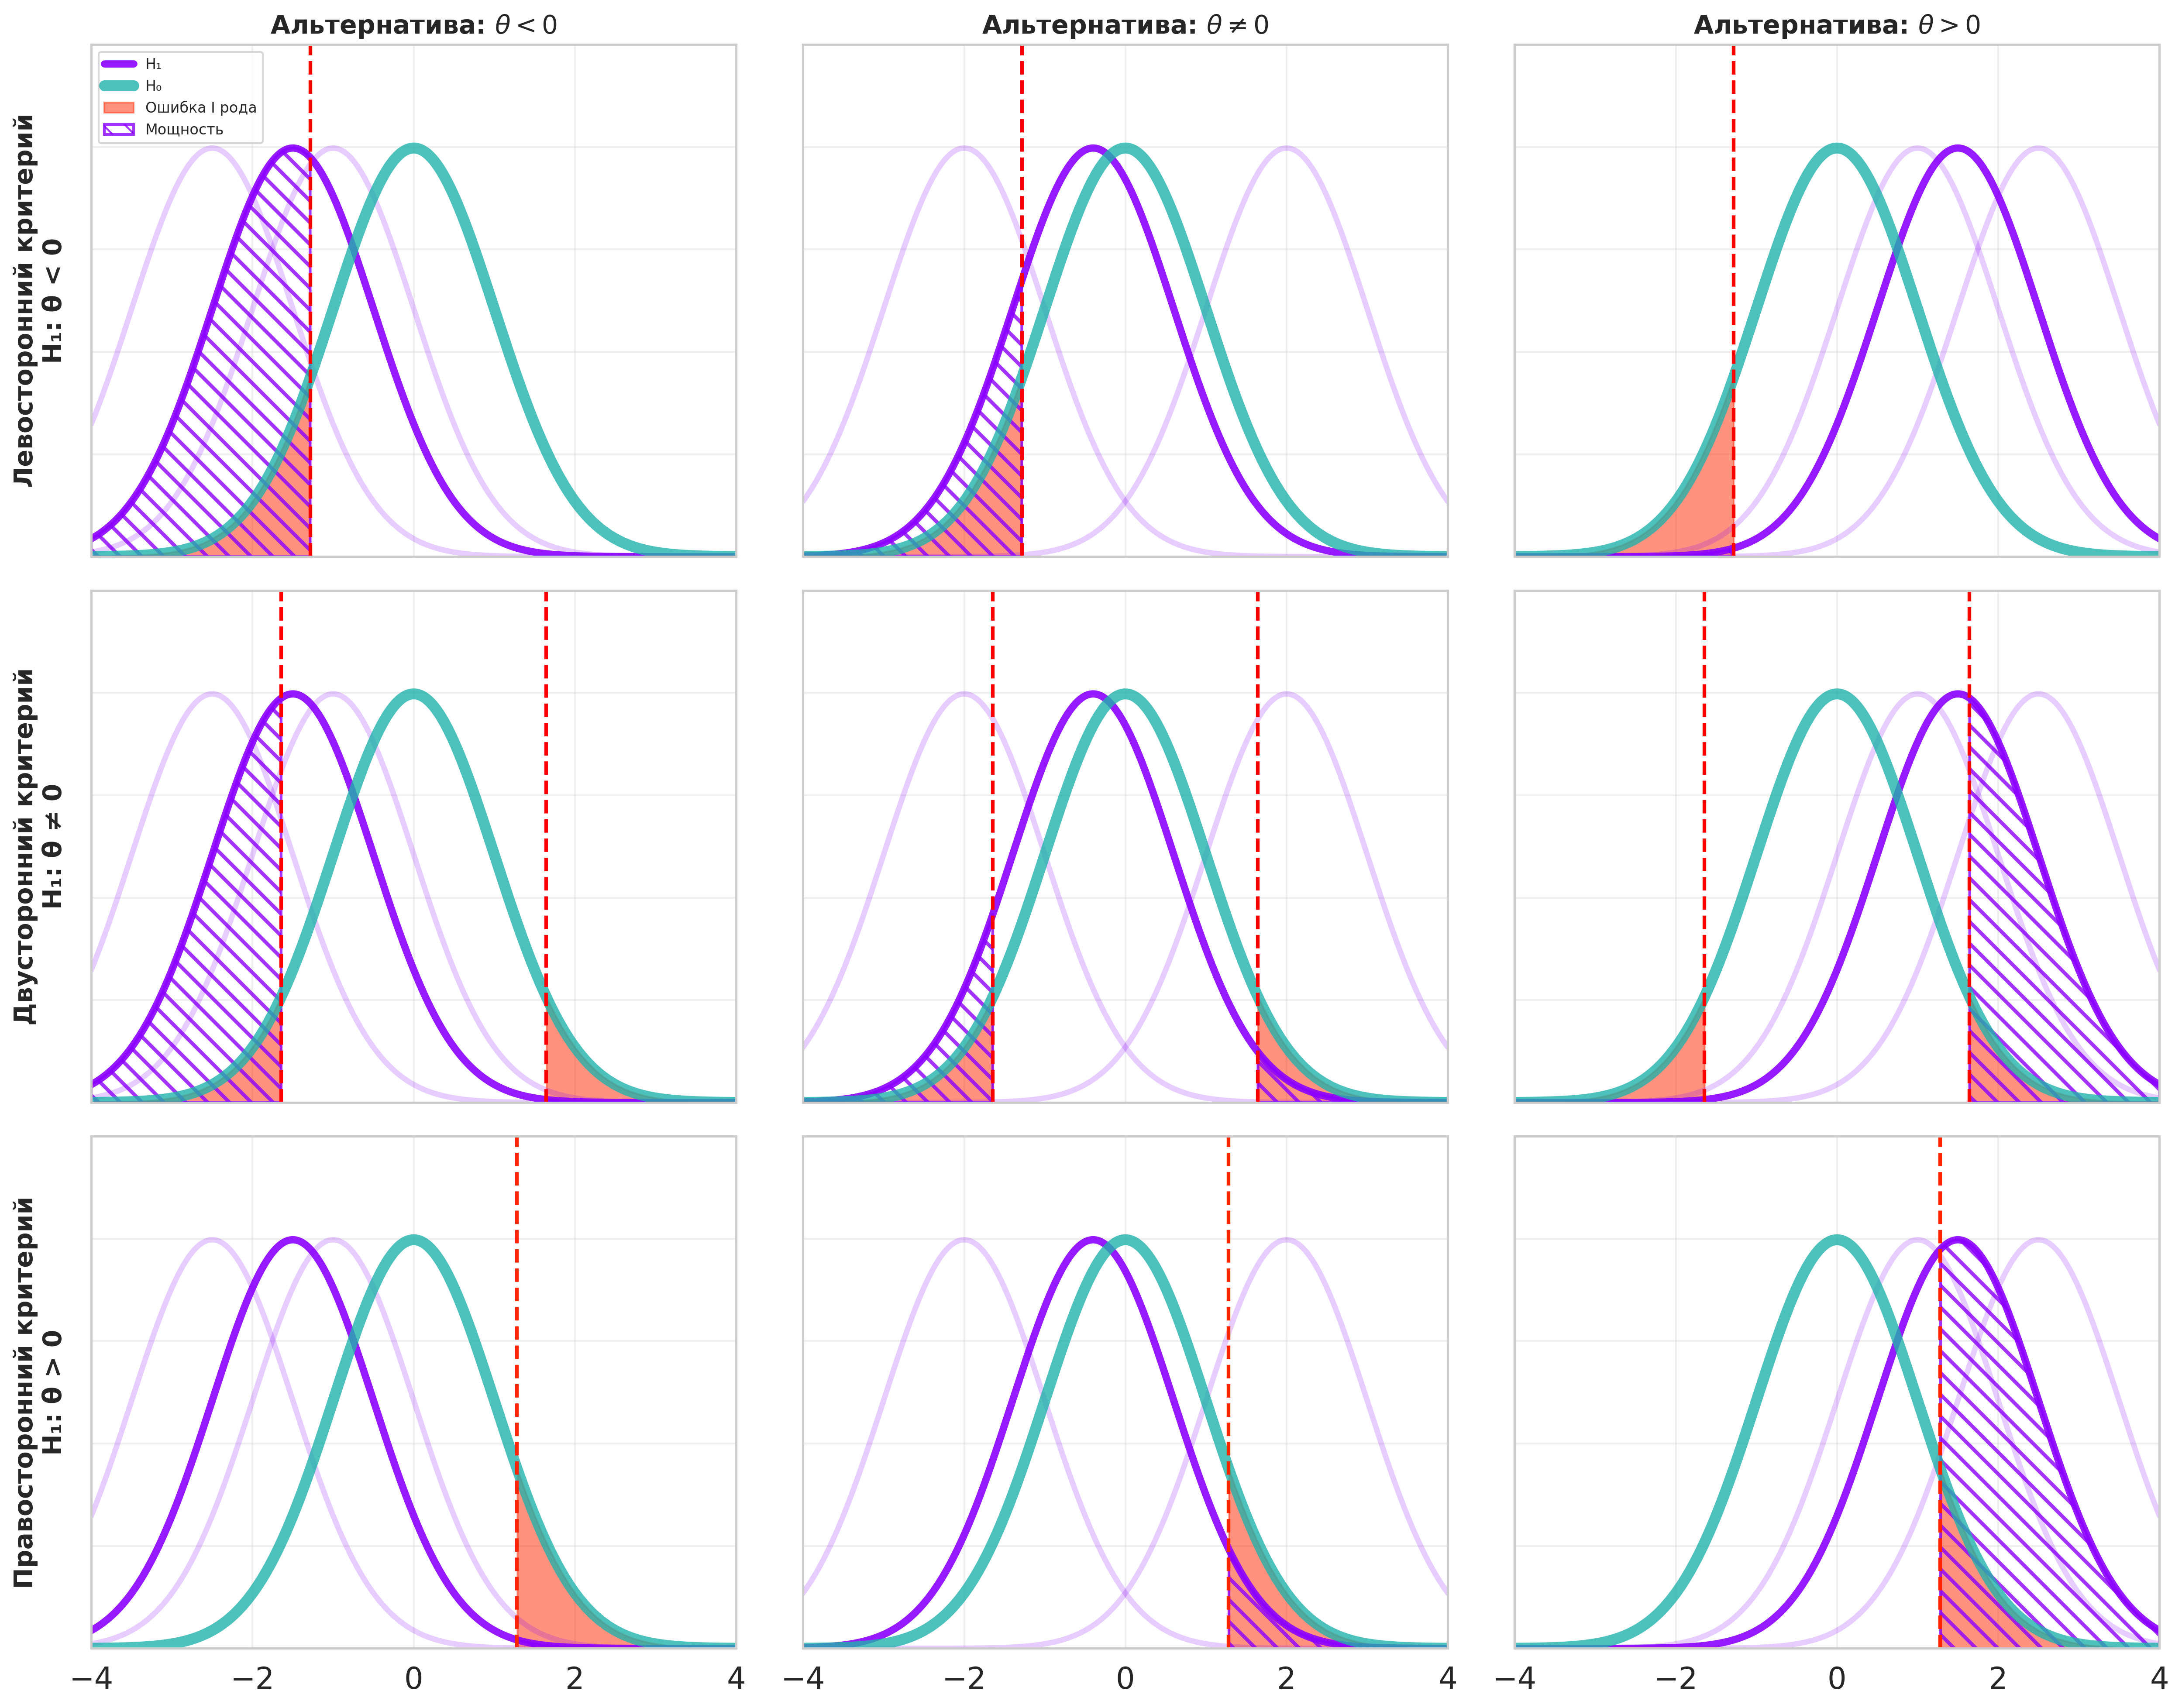

&#x2757; **Интерактив** &#x2757;

Имеется следующий критерий: $S = \{ |W(x)| < c_{\alpha} \}$. Как в этом случае будут выглядеть графики из предыдущего пункта?

<details>
  <summary> Кликни для показа ответа </summary>

Итак, критерий строится так, чтобы ошибка первого рода не превышала заданный $\alpha$, т.е.нужно, чтобы закрашенная площадь была не более $\alpha$

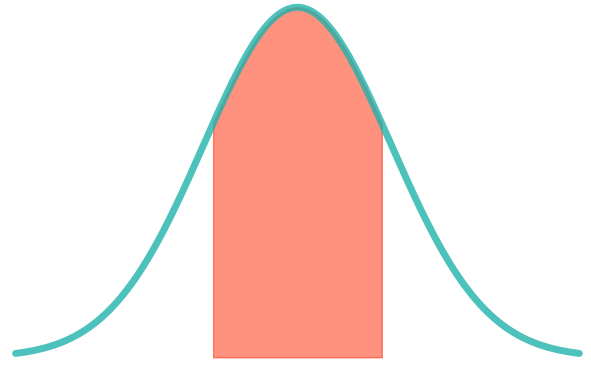

Такое будет соответствовать  $c_{\alpha} = z_{\frac{1+\alpha}{2}} $

А далее все стандартно. Результат такой

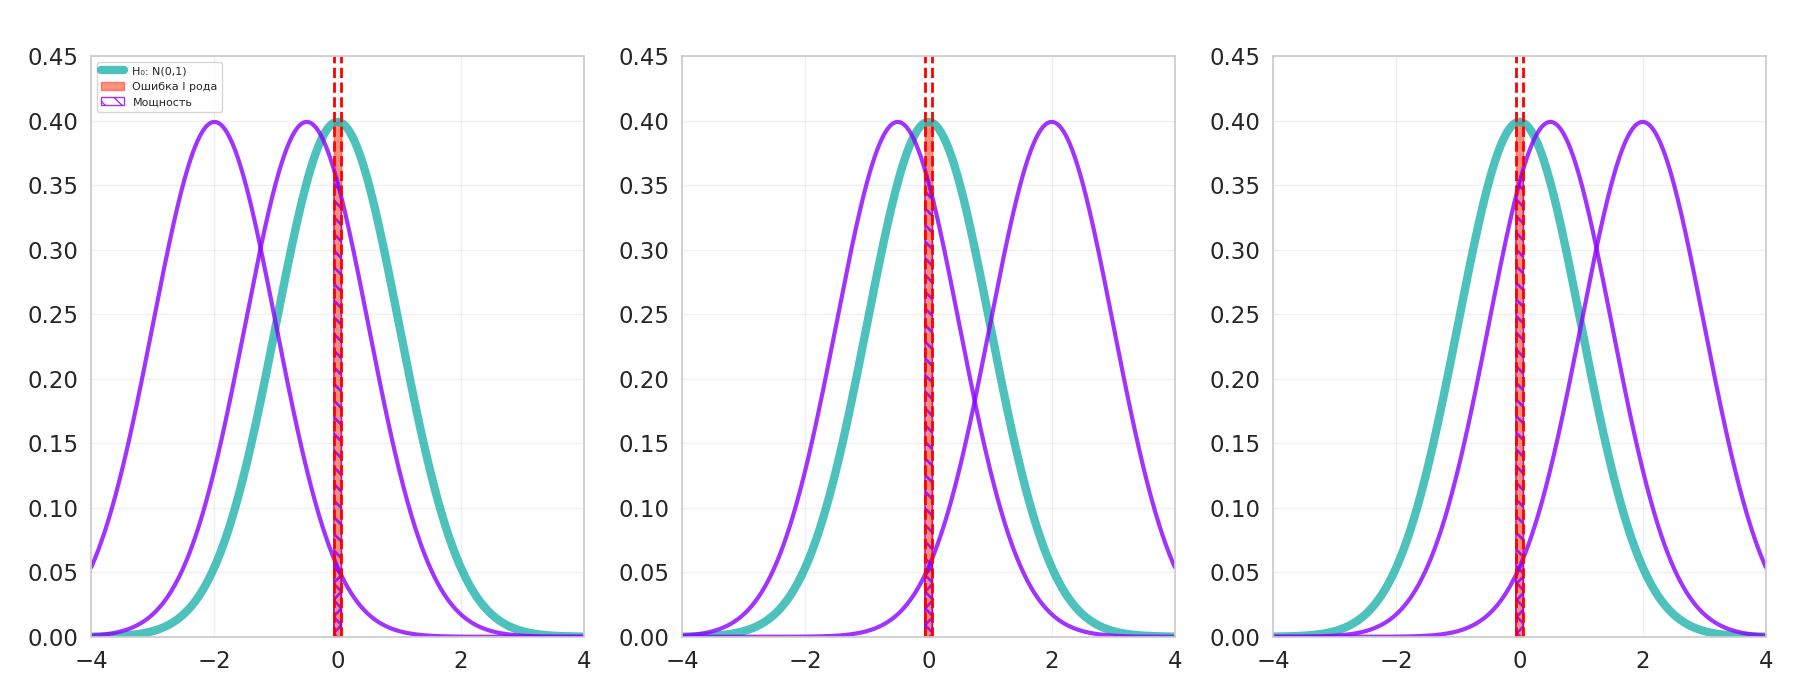

или если приблизить

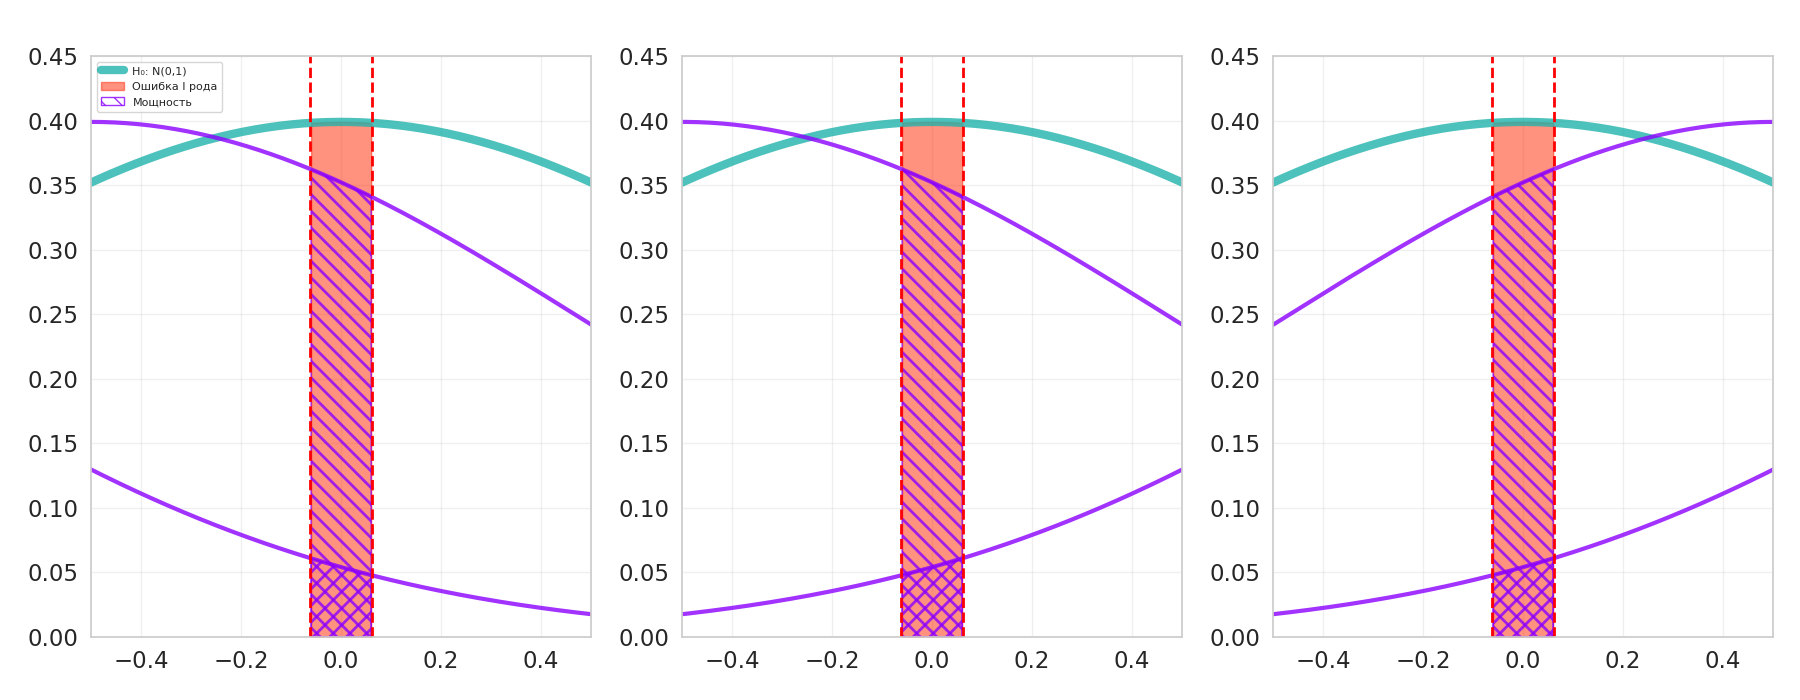
Такой критерий соответствует гипотезе

$\mathsf{H}_0: \theta \neq 0 $ vs $\mathsf{H}_1: \theta = 0$

</details><br/>


## Мощность критерия Вальда

Рассмотрим некоторое семейство распределений $\mathscr{P} = \{\mathsf{P}_\theta\ |\ \theta \in \Theta\}$ и нулевую гипотезу $\mathsf{H}_0\colon  \theta = \theta_0$.

Известно, что для проверки такой гипотезы в случае выполнения ЦПТ для $\mathsf{P}_\theta$ можно воспользоваться критерием Вальда. Однако при разных альтернативах используются разные виды критериев.

Напишем функции для вычисления мощности критериев Вальда разного вида.

In [13]:
def _wald_statistics(
    theta: Union[float, np.ndarray], theta0: float, n: int, sigma_est: float, alpha: float
) -> Any:
    r"""Вычисляет статистику Вальда.

    Аргументы:
        theta : float или np.ndarray
            Истинное значение параметра или массив значений.
        theta0 : float
            Значение параметра при нулевой гипотезе $\mathsf{H}_0$.
        n : int
            Положительный размер выборки.
        sigma_est : float
            Положительная оценка стандартного отклонения.
        alpha : float
            Уровень значимости, строго между 0 и 1; проверяется, но в формулу сдвига не входит.

    Возвращает:
        float или np.ndarray
            Значение $\sqrt{n}(\theta - \theta_0)/\mathrm{sigma\_est}$;
    """
    _validate_n(n)
    _validate_alpha(alpha)
    if sigma_est <= 0:
        raise ValueError("Стандартное отклонение должно быть положительным")
    return np.sqrt(n) * (np.asarray(theta) - theta0) / sigma_est


def wald_power_two_sided(
    theta: Union[float, np.ndarray], theta0: float, n: int, sigma_est: float, alpha: float = 0.05
) -> Any:
    r"""Вычисляет мощность двустороннего критерия Вальда для $\mathsf{H}_1: \theta \ne \theta_0$.

    Аргументы:
        theta : float или np.ndarray
            Истинное значение параметра или массив значений.
        theta0 : float
            Значение параметра при нулевой гипотезе $\mathsf{H}_0$.
        n : int
            Положительный размер выборки.
        sigma_est : float
            Положительная оценка стандартного отклонения.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        float или np.ndarray
            Вероятность отвержения нулевой гипотезы при заданном theta из $\mathsf{H}_1$.
    """
    omega = _wald_shift(theta, theta0, n, sigma_est, alpha)
    return sps.norm.sf(sps.norm.ppf(1 - alpha / 2) - omega) + sps.norm.cdf(
        sps.norm.ppf(alpha / 2) - omega
    )


def wald_power_left_sided(
    theta: Union[float, np.ndarray], theta0: float, n: int, sigma_est: float, alpha: float = 0.05
) -> Any:
    r"""Вычисляет мощность левостороннего критерия Вальда для $\mathsf{H}_1: \theta < \theta_0$.

    Аргументы:
        theta : float или np.ndarray
            Истинное значение параметра или массив значений.
        theta0 : float
            Значение параметра при нулевой гипотезе $\mathsf{H}_0$.
        n : int
            Положительный размер выборки.
        sigma_est : float
            Положительная оценка стандартного отклонения.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        float или np.ndarray
            Вероятность отвержения нулевой гипотезы при заданном theta из $\mathsf{H}_1$.
    """
    omega = _wald_statistics(theta, theta0, n, sigma_est, alpha)
    return sps.norm.cdf(sps.norm.ppf(alpha) - omega)


def wald_power_right_sided(
    theta: Union[float, np.ndarray], theta0: float, n: int, sigma_est: float, alpha: float = 0.05
) -> Any:
    r"""Вычисляет мощность правостороннего критерия Вальда для $\mathsf{H}_1: \theta > \theta_0$.

    Аргументы:
        theta : float или np.ndarray
            Истинное значение параметра или массив значений.
        theta0 : float
            Значение параметра при нулевой гипотезе $\mathsf{H}_0$.
        n : int
            Положительный размер выборки.
        sigma_est : float
            Положительная оценка стандартного отклонения.
        alpha : float, по умолчанию 0.05
            Уровень значимости, строго между 0 и 1.

    Возвращает:
        float или np.ndarray
            Вероятность отвержения нулевой гипотезы при заданном theta из $\mathsf{H}_1$.
    """
    omega = _wald_statistics(theta, theta0, n, sigma_est, alpha)
    return sps.norm.sf(sps.norm.ppf(1 - alpha) - omega)

Зададим параметры в виде слайдеров и визуализируем на графике полученные мощности.

In [14]:
render_demo("power", calculations_js=CALCULATIONS_JS)

**Выводы**

При увеличении размера выборки даже маленькие отклонения начинают улавливаться с большей мощностью, то есть растить размер выборки полезно.

При изменении $\theta_0$ графики просто параллельно переносятся.

При увеличении уровня значимости можно делать больше ошибок, а значит чаще отвергать. Поэтому мощность так же растёт. А при $\theta = \theta_0$ значение мощности увеличивается до $\alpha$.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>